In [3]:
import sys
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt

from src.config import AudioConfig
from src.audio import load_audio, process_audio

In [4]:
file_path = AudioConfig.audio_dir / "1-137-A-32.wav"

audio, sr = load_audio(file_path)

c:\Users\PC\Documents\GitHub\BaiTapCuoiKy_DeepLearning_2026_HK1\.venv\Lib\site-packages\torchaudio\_backend\utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


In [7]:
audio.shape

torch.Size([1, 220500])

In [6]:
sr

44100

In [18]:
config = AudioConfig()

processed_audio = process_audio(file_path, config)

In [19]:
processed_audio.shape

torch.Size([1, 110250])

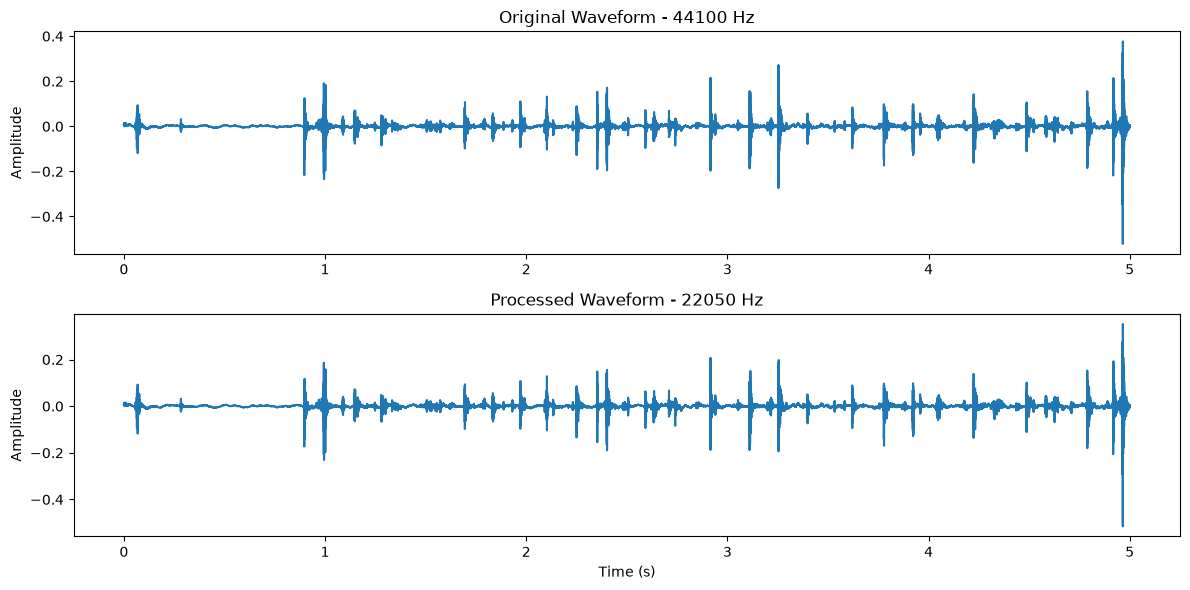

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

raw_time = torch.arange(audio.shape[-1]) / sr
processed_time = torch.arange(processed_audio.shape[-1]) / AudioConfig.sample_rate

axes[0].plot(raw_time, audio[0])
axes[0].set_title("Original Waveform - 44100 Hz")
axes[0].set_ylabel("Amplitude")

axes[1].plot(processed_time, processed_audio[0])
axes[1].set_title("Processed Waveform - 22050 Hz")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [25]:
from src.audio import to_mono, pad_or_trim

# Test 1: Stereo -> Mono
stereo = torch.randn(2, 1000)
mono = to_mono(stereo)

assert mono.shape == (1, 1000)

# Test 2: Padding
short_audio = torch.ones(1, 100)
padded = pad_or_trim(short_audio, 200)

assert padded.shape == (1, 200)
assert torch.all(padded[0, 100:] == 0)

# Test 3: Trimming
long_audio = torch.ones(1, 300)
trimmed = pad_or_trim(long_audio, 200)

assert trimmed.shape == (1, 200)

# Test 4: Real WAV
assert processed_audio.shape == (1, config.num_samples)
assert processed_audio.dtype == torch.float32
assert torch.isfinite(processed_audio).all()

print("All tests passed!")

All tests passed!


In [26]:
import pandas as pd

df = pd.read_csv(AudioConfig.metadata_file)

In [28]:
errors = []

for filename in df["filename"]:
    try:
        waveform = process_audio(AudioConfig.audio_dir / filename, config)
        assert waveform.shape == (1, config.num_samples)
    except Exception as e:
        errors.append((filename, str(e)))

print("số lượng file lỗi:", len(errors))


c:\Users\PC\Documents\GitHub\BaiTapCuoiKy_DeepLearning_2026_HK1\.venv\Lib\site-packages\torchaudio\_backend\utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


số lượng file lỗi: 0


In [30]:
from src.config import FeatureConfig
from src.features import LogMelSpectrogram, plot_spectrogram

In [31]:
feature_config = FeatureConfig()

In [38]:
feature_extractor = LogMelSpectrogram(
    sample_rate=22050,
    n_fft=feature_config.n_fft,
    hop_length=feature_config.hop_length,
    n_mels=feature_config.n_mels
)

features = feature_extractor(processed_audio)

In [40]:
processed_audio.shape

torch.Size([1, 110250])

In [41]:
features.shape

torch.Size([1, 128, 216])

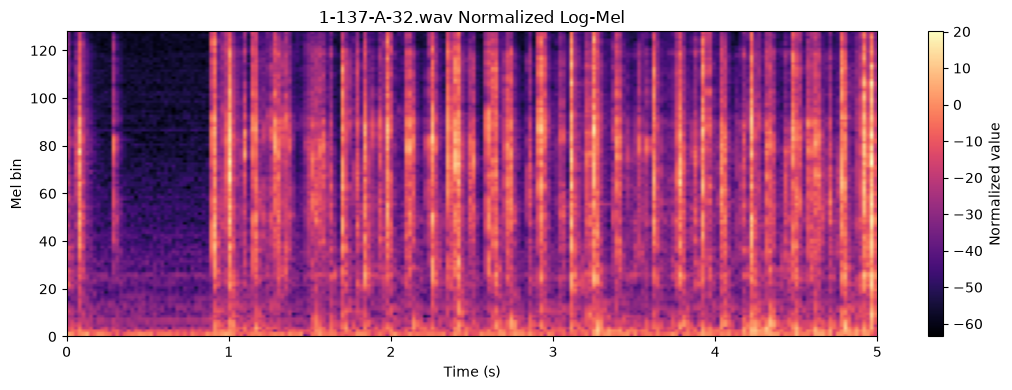

In [46]:
plot_spectrogram(
    features,
    duration=AudioConfig.duration,
    title=f"{str(file_path.name)} Normalized Log-Mel",
    normalized=True
)
plt.show()